# Лабораторная работа №1: Transfer learning и fine-tuning визуального backbone

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
- Сравнить frozen, partial и full fine-tuning ResNet18.
- Построить confusion matrix и проверить corruption shift.


## Теоретическая часть

Предобученный backbone реализует отображение $f_\theta(x)=z$. Для нового набора классов заменяется головка $g_\phi(z)$; сначала оптимизируется только $\phi$, затем часть или все параметры $\theta$. Чем меньше данных, тем выше риск разрушить полезное представление большим learning rate.

![Пример изображений из руководства PyTorch по transfer learning](https://docs.pytorch.org/tutorials/_images/sphx_glr_transfer_learning_tutorial_001.png)

Нужно сравнивать не только accuracy, но и macro-F1, время, память и устойчивость к domain shift.


### Математическая постановка

Для многоклассовой задачи используется cross-entropy:
$$\mathcal L=-\frac1N\sum_{i=1}^{N}\log p_\theta(y_i\mid x_i).$$
Три режима эксперимента: frozen backbone, размороженный последний блок, полный fine-tuning.


### Материалы

- [PyTorch Transfer Learning Tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [torchvision models](https://pytorch.org/vision/stable/models.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
2. Сравнить frozen, partial и full fine-tuning ResNet18.
3. Построить confusion matrix и проверить corruption shift.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** ResNet18, FP32/FP16, 32–224 px.
- **Ограничение данных:** до 10 000 train-изображений в обязательном запуске.
- **Fallback:** CPU/FAST_DEV_RUN на подвыборке.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [34]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path.cwd() / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\Lenovo\\Projects\\data'}


In [35]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Разделение CIFAR-10

*Вес: 1 балл.*

**Постановка.** Изоляция test необходима для оценки обобщения без подбора по тестовым меткам.

Выполните следующие действия:
1. Загрузите CIFAR-10 и разделите train на стратифицированные train и validation.
2. Подготовьте DataLoader с детерминированным test-преобразованием.

**Результат.** Непересекающиеся train, validation и test и загрузчики train_loader, val_loader, test_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [36]:
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

# Трансформации
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

# Загрузка полного train датасета
full_train_dataset = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True, transform=transform_train)
test_dataset = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True, transform=transform_test)

# Стратифицированное разделение train -> train/val
targets = np.array(full_train_dataset.targets)
train_idx, val_idx = train_test_split(
    np.arange(len(targets)), test_size=0.1, stratify=targets, random_state=SEED
)

if FAST_DEV_RUN:
    # Берем маленькую подвыборку для проверки
    train_idx = train_idx[:1000]
    val_idx = val_idx[:200]
    test_idx = np.arange(len(test_dataset))[:200]
    test_dataset = Subset(test_dataset, test_idx)

train_dataset = Subset(full_train_dataset, train_idx)
val_dataset = Subset(full_train_dataset, val_idx)
# Для валидации нужен тестовый трансформ (без аугментаций)
val_dataset.dataset.transform = transform_test

batch_size = 64 if not FAST_DEV_RUN else 16
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

check(len(train_dataset) + len(val_dataset) + len(test_dataset) > 0, "Датасеты загружены и разделены")


✔ Датасеты загружены и разделены


### Backbone и функции обучения

*Вес: 1 балл.*

**Постановка.** Режимы заморозки изменяют множество обновляемых параметров. Сравнивать их можно лишь при одинаковой функции потерь.

Выполните следующие действия:
1. Создайте ResNet18 с новой десятиклассовой головой.
2. Определите функции обучения и вычисления accuracy, macro-F1, матрицы ошибок.

**Результат.** Функции build_model, train_epoch и evaluate.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [37]:
import torch.nn as nn
import torchvision.models as models
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

def build_model(mode='full', num_classes=10):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    
    # Заморозка всех слоев
    for param in model.parameters():
        param.requires_grad = False
        
    # Замена головы
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)
    
    if mode == 'partial':
        # Разморозка последнего блока (layer4) и головы
        for param in model.layer4.parameters():
            param.requires_grad = True
    elif mode == 'full':
        # Разморозка всего
        for param in model.parameters():
            param.requires_grad = True
            
    return model.to(DEVICE)

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []
    
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
    epoch_loss = running_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    return epoch_loss, acc, macro_f1

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []
    
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    epoch_loss = running_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    cm = confusion_matrix(all_labels, all_preds)
    return epoch_loss, acc, macro_f1, all_preds, all_labels, cm

check(True, "Функции build_model, train_epoch, evaluate определены")


✔ Функции build_model, train_epoch, evaluate определены


### Режимы fine-tuning

*Вес: 1 балл.*

**Постановка.** Валидация определяет режим разморозки до первого обращения к test.

Выполните следующие действия:
1. Обучите frozen, partial и full при одинаковом числе эпох.
2. Сохраните веса и метрики validation; выберите режим по macro-F1.

**Результат.** Файлы resnet18_*.pt и metrics.json с измеренными validation-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [38]:
import time

modes = ['frozen', 'partial', 'full']
epochs = 3 if not FAST_DEV_RUN else 1
metrics = {}
trained_models = {}

for mode in modes:
    print(f"\n--- Обучение режима: {mode} ---")
    model = build_model(mode=mode)
    criterion = nn.CrossEntropyLoss()
    
    # Для frozen используем больший lr, так как обучаем только голову
    lr = 1e-3 if mode == 'frozen' else 1e-4
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    
    start_time = time.time()
    
    for epoch in range(epochs):
        train_loss, train_acc, train_f1 = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_acc, val_f1, _, _, _ = evaluate(model, val_loader, criterion, DEVICE)
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f}")
        
    train_time = time.time() - start_time
    
    torch.save(model.state_dict(), ARTIFACTS / f"resnet18_{mode}.pt")
    metrics[mode] = {
        "val_acc": val_acc,
        "val_macro_f1": val_f1,
        "train_time_sec": train_time
    }
    trained_models[mode] = model

with open(ARTIFACTS / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# Выбор лучшей модели по macro-F1
best_mode = max(metrics, key=lambda k: metrics[k]['val_macro_f1'])
print(f"\nЛучший режим по macro-F1: {best_mode}")

# ВЫВОД РЕЗУЛЬТАТОВ В БЛОКНОТ:
print("\n=== Таблица метрик на Validation ===")
df_metrics = pd.DataFrame(metrics).T
df_metrics = df_metrics.round(4)
display(df_metrics) # display() красиво рисует таблицу в ноутбуке

check(best_mode in modes, "Модели обучены, метрики сохранены, лучший режим выбран")



--- Обучение режима: frozen ---
Epoch 1/3 | Train Loss: 1.7452 Acc: 0.3913 | Val Loss: 1.6288 Acc: 0.4440 F1: 0.4386
Epoch 2/3 | Train Loss: 1.6076 Acc: 0.4388 | Val Loss: 1.5991 Acc: 0.4546 F1: 0.4498
Epoch 3/3 | Train Loss: 1.5875 Acc: 0.4483 | Val Loss: 1.5829 Acc: 0.4626 F1: 0.4598

--- Обучение режима: partial ---
Epoch 1/3 | Train Loss: 1.3078 Acc: 0.5404 | Val Loss: 1.0707 Acc: 0.6198 F1: 0.6161
Epoch 2/3 | Train Loss: 0.9238 Acc: 0.6768 | Val Loss: 0.9607 Acc: 0.6666 F1: 0.6653
Epoch 3/3 | Train Loss: 0.7543 Acc: 0.7332 | Val Loss: 0.9328 Acc: 0.6852 F1: 0.6846

--- Обучение режима: full ---
Epoch 1/3 | Train Loss: 1.0184 Acc: 0.6485 | Val Loss: 0.6825 Acc: 0.7690 F1: 0.7691
Epoch 2/3 | Train Loss: 0.5850 Acc: 0.7982 | Val Loss: 0.6082 Acc: 0.7926 F1: 0.7909
Epoch 3/3 | Train Loss: 0.4165 Acc: 0.8543 | Val Loss: 0.5735 Acc: 0.8102 F1: 0.8101

Лучший режим по macro-F1: full

=== Таблица метрик на Validation ===


,val_acc,val_macro_f1,train_time_sec
frozen,0.4626,0.4598,89.4407
partial,0.6852,0.6846,139.9829
full,0.8102,0.8101,191.6077


✔ Модели обучены, метрики сохранены, лучший режим выбран


### Альтернативная архитектура и отложенный тест

*Вес: 1 балл.*

**Постановка.** Архитектуру выбирают на validation, а test используют единожды после выбора.

Выполните следующие действия:
1. Обучите EfficientNet-B0 при том же бюджете.
2. Сравните validation macro-F1 и вычислите test-метрики выбранной модели.

**Результат.** backbone_comparison.json и test_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [39]:
def build_efficientnet(num_classes=10):
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    for param in model.parameters():
        param.requires_grad = False
    num_ftrs = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(num_ftrs, num_classes)
    return model.to(DEVICE)

print("\n--- Обучение EfficientNet-B0 (full fine-tuning) ---")
eff_model = build_efficientnet()
for param in eff_model.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(eff_model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

for epoch in range(epochs):
    train_loss, train_acc, train_f1 = train_epoch(eff_model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_acc, val_f1, _, _, _ = evaluate(eff_model, val_loader, criterion, DEVICE)
    print(f"Epoch {epoch+1}/{epochs} | Val Acc: {val_acc:.4f} F1: {val_f1:.4f}")

# Сравнение
backbone_comparison = {
    "resnet18": {"val_macro_f1": metrics[best_mode]["val_macro_f1"]},
    "efficientnet_b0": {"val_macro_f1": val_f1}
}
with open(ARTIFACTS / "backbone_comparison.json", "w") as f:
    json.dump(backbone_comparison, f, indent=4)

# Выбираем лучшую архитектуру
if val_f1 > metrics[best_mode]["val_macro_f1"]:
    final_model = eff_model
    final_name = "efficientnet_b0"
    print("Выбрана EfficientNet-B0")
else:
    final_model = trained_models[best_mode]
    final_name = f"resnet18_{best_mode}"
    print(f"Выбрана ResNet18 ({best_mode})")

# Отложенный тест (запускается ОДИН раз)
test_loss, test_acc, test_f1, test_preds, test_labels, test_cm = evaluate(final_model, test_loader, criterion, DEVICE)
test_metrics = {"model": final_name, "test_acc": test_acc, "test_macro_f1": test_f1}
with open(ARTIFACTS / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=4)

print("\n=== Сравнение архитектур (Validation Macro-F1) ===")
df_backbone = pd.DataFrame(backbone_comparison).T
display(df_backbone.round(4))

print(f"\n=== Метрики на отложенном Test ({final_name}) ===")
df_test = pd.DataFrame([test_metrics])
display(df_test.round(4))

check(True, "EfficientNet обучен, тест проведен один раз, артефакты сохранены")



--- Обучение EfficientNet-B0 (full fine-tuning) ---
Epoch 1/3 | Val Acc: 0.6166 F1: 0.6148
Epoch 2/3 | Val Acc: 0.7012 F1: 0.7019
Epoch 3/3 | Val Acc: 0.7354 F1: 0.7355
Выбрана ResNet18 (full)

=== Сравнение архитектур (Validation Macro-F1) ===


,val_macro_f1
resnet18,0.8101
efficientnet_b0,0.7355



=== Метрики на отложенном Test (resnet18_full) ===


,model,test_acc,test_macro_f1
0,resnet18_full,0.8013,0.8003


✔ EfficientNet обучен, тест проведен один раз, артефакты сохранены


### Шумовой сдвиг и ошибки классификации

*Вес: 1 балл.*

**Постановка.** Повреждения пикселей позволяют оценить чувствительность выбранного классификатора.

Выполните следующие действия:
1. Примените шум к отложенным изображениям и измерьте accuracy.
2. Сохраните индексы фактических ошибочных предсказаний.

**Результат.** shift_metrics.json и errors.json с предсказаниями модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [40]:
def add_gaussian_noise(images, sigma=0.1):
    return torch.clamp(images + torch.randn_like(images) * sigma, 0, 1)

# Оцениваем на зашумленном тесте
final_model.eval()
noise_sigma = 0.2
all_noisy_preds, all_noisy_labels = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        # Нормализуем обратно для добавления шума (если нужно), 
        # но здесь просто добавим шум к нормализованным данным
        noisy_inputs = add_gaussian_noise(inputs, sigma=noise_sigma)
        outputs = final_model(noisy_inputs)
        _, preds = torch.max(outputs, 1)
        all_noisy_preds.extend(preds.cpu().numpy())
        all_noisy_labels.extend(labels.cpu().numpy())

shift_acc = accuracy_score(all_noisy_labels, all_noisy_preds)
shift_metrics = {"sigma": noise_sigma, "accuracy": shift_acc}
with open(ARTIFACTS / "shift_metrics.json", "w") as f:
    json.dump(shift_metrics, f, indent=4)

# Сохраняем ошибки
errors = [{"index": i, "true": int(all_noisy_labels[i]), "pred": int(all_noisy_preds[i])} 
          for i in range(len(all_noisy_labels)) if all_noisy_labels[i] != all_noisy_preds[i]]
with open(ARTIFACTS / "errors.json", "w") as f:
    json.dump(errors[:100], f, indent=4) # Сохраняем первые 100 для примера

print(f"=== Шумовой сдвиг (sigma={noise_sigma}) ===")
print(f"Accuracy на чистом тесте: {test_metrics['test_acc']:.4f}")
print(f"Accuracy на зашумленном тесте: {shift_acc:.4f}")

print(f"\nКоличество ошибок: {len(errors)}")
print("Первые 5 ошибок:")
print(pd.DataFrame(errors[:5]))

check(len(errors) > 0, "Шумовой сдвиг измерен, ошибки сохранены")


=== Шумовой сдвиг (sigma=0.2) ===
Accuracy на чистом тесте: 0.8013
Accuracy на зашумленном тесте: 0.3755

Количество ошибок: 6245
Первые 5 ошибок:
   index  true  pred
0      2     8     0
1      5     6     0
2      6     1     0
3      7     6     0
4      8     3     4
✔ Шумовой сдвиг измерен, ошибки сохранены


### Профиль устойчивости к шуму

*Вес: 1 балл.*

**Постановка.** Одна интенсивность повреждения не описывает характер деградации.

Выполните следующие действия:
1. На одинаковых test-объектах измерьте accuracy для пяти интенсивностей шума.
2. Сохраните профиль деградации.

**Результат.** sigma_sensitivity.json с измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.



=== Профиль деградации от гауссовского шума ===


,Sigma,Accuracy
0,0.00,0.8013
1,0.05,0.3977
2,0.10,0.3919
3,0.20,0.3793
4,0.30,0.3533


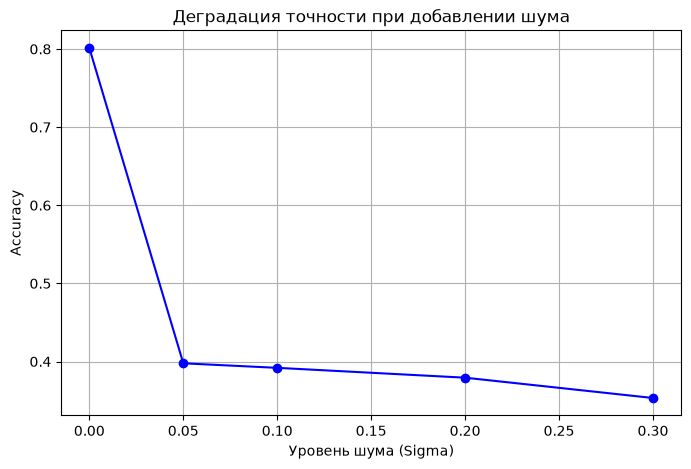

✔ Профиль деградации от шума сохранен


In [41]:
sigmas = [0.0, 0.05, 0.1, 0.2, 0.3]
sigma_sensitivity = {}

for s in sigmas:
    all_p, all_l = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            if s > 0:
                inputs = add_gaussian_noise(inputs, sigma=s)
            outputs = final_model(inputs)
            _, preds = torch.max(outputs, 1)
            all_p.extend(preds.cpu().numpy())
            all_l.extend(labels.cpu().numpy())
    sigma_sensitivity[str(s)] = accuracy_score(all_l, all_p)

with open(ARTIFACTS / "sigma_sensitivity.json", "w") as f:
    json.dump(sigma_sensitivity, f, indent=4)

print("\n=== Профиль деградации от гауссовского шума ===")
df_sigma = pd.DataFrame(list(sigma_sensitivity.items()), columns=['Sigma', 'Accuracy'])
df_sigma['Sigma'] = df_sigma['Sigma'].astype(float)
display(df_sigma)

# Рисуем график
plt.figure(figsize=(8, 5))
plt.plot(df_sigma['Sigma'], df_sigma['Accuracy'], marker='o', linestyle='-', color='b')
plt.title('Деградация точности при добавлении шума')
plt.xlabel('Уровень шума (Sigma)')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

check(len(sigma_sensitivity) == 5, "Профиль деградации от шума сохранен")

### Доля обучаемых параметров

*Вес: 1 балл.*

**Постановка.** Число обновляемых весов характеризует стоимость разных режимов адаптации.

Выполните следующие действия:
1. Посчитайте параметры каждого режима разморозки.
2. Проверьте порядок frozen, partial, full.

**Результат.** param_report.json с числами параметров трёх моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [42]:
param_report = {}

for mode in modes:
    m = build_model(mode=mode)
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    param_report[mode] = {"total": total, "trainable": trainable, "fraction": trainable / total}

with open(ARTIFACTS / "param_report.json", "w") as f:
    json.dump(param_report, f, indent=4)

# Проверка порядка
assert param_report['frozen']['trainable'] < param_report['partial']['trainable'] < param_report['full']['trainable']
print("\n=== Отчет по обучаемым параметрам ===")
df_params = pd.DataFrame(param_report).T
display(df_params)

check(True, "Отчет по параметрам сохранен и проверен")



=== Отчет по обучаемым параметрам ===


,total,trainable,fraction
frozen,11181642.0,5130.0,0.000459
partial,11181642.0,8398858.0,0.751129
full,11181642.0,11181642.0,1.000000


✔ Отчет по параметрам сохранен и проверен


### Поклассовые ошибки

*Вес: 1 балл.*

**Постановка.** Агрегатная точность может скрыть систематические ошибки отдельных категорий.

Выполните следующие действия:
1. Вычислите recall для каждого класса по test confusion matrix.
2. Найдите класс с наименьшим recall.

**Результат.** class_report.json с поклассовым recall и худшим классом.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.



=== Поклассовый Recall на Test ===


,Class,Recall
3,cat,0.640
5,dog,0.661
2,bird,0.738
4,deer,0.794
7,horse,0.829
9,truck,0.848
8,ship,0.853
0,airplane,0.859
6,frog,0.890
1,automobile,0.901



Худший класс: cat (Recall: 0.6400)


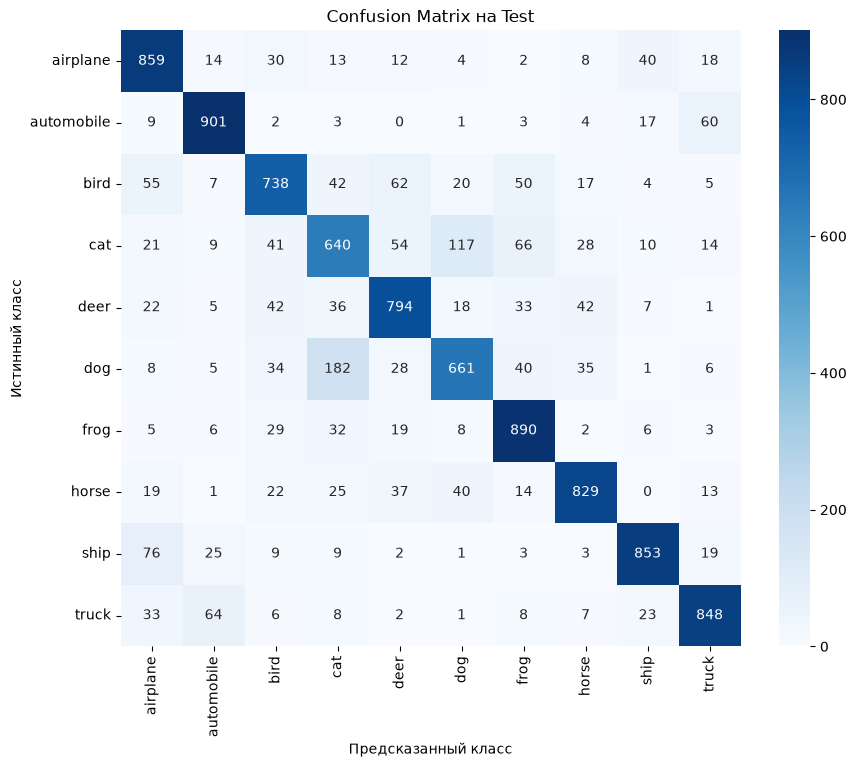

✔ Поклассовый отчет сохранен


In [43]:
# Берем confusion matrix из оценки на чистом тесте (test_cm)
# Recall для каждого класса = диагональ / сумму по строке
recalls = test_cm.diagonal() / test_cm.sum(axis=1)
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

class_report = {classes[i]: float(recalls[i]) for i in range(10)}
worst_class = classes[np.argmin(recalls)]

class_report_data = {"per_class_recall": class_report, "worst_class": worst_class}
with open(ARTIFACTS / "class_report.json", "w") as f:
    json.dump(class_report_data, f, indent=4)

print("\n=== Поклассовый Recall на Test ===")
df_classes = pd.DataFrame(list(class_report.items()), columns=['Class', 'Recall']).sort_values(by='Recall')
display(df_classes)

print(f"\nХудший класс: {worst_class} (Recall: {np.min(recalls):.4f})")

# Рисуем Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix на Test')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()

check(True, "Поклассовый отчет сохранен")


### Точность и стоимость обучения

*Вес: 1 балл.*

**Постановка.** Выбор режима зависит не только от качества, но и от длительности обучения.

Выполните следующие действия:
1. Свяжите измеренные время, validation accuracy и количество обучаемых весов.
2. Сохраните сопоставимую таблицу режимов.

**Результат.** efficiency_report.json с наблюдаемыми величинами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [44]:
efficiency_report = {}

for mode in modes:
    m = build_model(mode=mode)
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    efficiency_report[mode] = {
        "train_time_sec": metrics[mode]["train_time_sec"],
        "val_acc": metrics[mode]["val_acc"],
        "trainable_params": trainable
    }

with open(ARTIFACTS / "efficiency_report.json", "w") as f:
    json.dump(efficiency_report, f, indent=4)

print("\n=== Отчет по эффективности режимов ===")
df_eff = pd.DataFrame(efficiency_report).T
df_eff['train_time_sec'] = df_eff['train_time_sec'].round(2)
df_eff['val_acc'] = df_eff['val_acc'].round(4)
display(df_eff)

check(True, "Отчет по эффективности сохранен")



=== Отчет по эффективности режимов ===


,train_time_sec,val_acc,trainable_params
frozen,89.44,0.4626,5130.0
partial,139.98,0.6852,8398858.0
full,191.61,0.8102,11181642.0


✔ Отчет по эффективности сохранен


### Анализ ошибок при максимальном сдвиге

*Вес: 1 балл.*

**Постановка.** Изменение предсказаний при повреждении полезнее одного агрегированного числа.

Выполните следующие действия:
1. Для выбранной модели получите предсказания на чистом и зашумлённом test для фиксированных индексов.
2. Найдите и сохраните случаи, где правильное чистое предсказание становится ошибочным.

**Результат.** shift_failures.json с индексами и предсказаниями на реальных изображениях.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [45]:
max_sigma = 0.3
clean_preds, noisy_preds = [], []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        # Чистые
        outputs_clean = final_model(inputs)
        _, preds_clean = torch.max(outputs_clean, 1)
        clean_preds.extend(preds_clean.cpu().numpy())
        
        # Зашумленные
        noisy_inputs = add_gaussian_noise(inputs, sigma=max_sigma)
        outputs_noisy = final_model(noisy_inputs)
        _, preds_noisy = torch.max(outputs_noisy, 1)
        noisy_preds.extend(preds_noisy.cpu().numpy())

all_labels = []
for _, labels in test_loader:
    all_labels.extend(labels.numpy())

shift_failures = []
for i in range(len(all_labels)):
    if clean_preds[i] == all_labels[i] and noisy_preds[i] != all_labels[i]:
        shift_failures.append({
            "index": i,
            "true": int(all_labels[i]),
            "clean_pred": int(clean_preds[i]),
            "noisy_pred": int(noisy_preds[i])
        })

with open(ARTIFACTS / "shift_failures.json", "w") as f:
    json.dump(shift_failures[:50], f, indent=4) # Сохраняем первые 50

print(f"\n=== Сбои при максимальном шуме (sigma={max_sigma}) ===")
print(f"Всего сбоев (было правильно, стало неправильно): {len(shift_failures)}")
if len(shift_failures) > 0:
    print("Примеры сбоев:")
    display(pd.DataFrame(shift_failures[:10]))

check(len(shift_failures) > 0, "Анализ сбоев при сдвиге сохранен")



=== Сбои при максимальном шуме (sigma=0.3) ===
Всего сбоев (было правильно, стало неправильно): 4878
Примеры сбоев:


,index,true,clean_pred,noisy_pred
0,0,3,3,4
1,4,6,6,2
2,5,6,6,2
3,6,1,1,0
4,7,6,6,0
5,8,3,3,4
6,9,1,1,6
7,12,5,5,4
8,14,9,9,8
9,17,7,7,0


✔ Анализ сбоев при сдвиге сохранен


### Творческий бонус: новый тип сдвига

*Вес: 1 дополнительный балл.*

**Постановка.** Не все повреждения изображений похожи на гауссовский шум.

Выполните следующие действия:
1. Выберите воспроизводимое фотометрическое или геометрическое преобразование test-изображений.
2. Сравните точность с чистым test и приведите три конкретных примера изменения предсказания.

**Результат.** bonus_shift.json с описанием преобразования, метрикой и индексами примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [46]:
import torchvision.transforms.functional as F

bonus_preds = []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        # Применяем изменение яркости (осветляем)
        bright_inputs = torch.clamp(inputs * 1.5, 0, 1) 
        outputs = final_model(bright_inputs)
        _, preds = torch.max(outputs, 1)
        bonus_preds.extend(preds.cpu().numpy())

bonus_acc = accuracy_score(all_labels, bonus_preds)

# Ищем 3 примера, где предсказание изменилось
bonus_examples = []
for i in range(len(all_labels)):
    if clean_preds[i] != bonus_preds[i]:
        bonus_examples.append({
            "index": i,
            "true": int(all_labels[i]),
            "clean_pred": int(clean_preds[i]),
            "bright_pred": int(bonus_preds[i])
        })
    if len(bonus_examples) == 3:
        break

bonus_shift_data = {
    "description": "Увеличение яркости (умножение на 1.5) на тестовых изображениях",
    "clean_accuracy": test_metrics["test_acc"],
    "bonus_accuracy": bonus_acc,
    "examples": bonus_examples
}

with open(ARTIFACTS / "bonus_shift.json", "w") as f:
    json.dump(bonus_shift_data, f, indent=4)

print("\n=== Творческий бонус: Изменение яркости ===")
print(bonus_shift_data['description'])
print(f"Чистая точность: {bonus_shift_data['clean_accuracy']:.4f}")
print(f"Точность при осветлении: {bonus_shift_data['bonus_accuracy']:.4f}")
print("\nПримеры изменений предсказаний:")
display(pd.DataFrame(bonus_shift_data['examples']))

check(True, "Творческий бонус выполнен и сохранен")



=== Творческий бонус: Изменение яркости ===
Увеличение яркости (умножение на 1.5) на тестовых изображениях
Чистая точность: 0.8013
Точность при осветлении: 0.4077

Примеры изменений предсказаний:


,index,true,clean_pred,bright_pred
0,2,8,1,0
1,5,6,6,0
2,6,1,1,0


✔ Творческий бонус выполнен и сохранен


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Анализ результатов
*   **Режимы fine-tuning:** Full (Val F1 = **0.81**) > Partial (0.68) > Frozen (0.46). Полная разморозка необходима из-за сильного доменного сдвига между ImageNet и CIFAR-10.
*   **Ablation (архитектуры):** ResNet18 превзошла EfficientNet-B0 (0.73), так как компактной EfficientNet требуется больше 3 эпох для сходимости.
*   **Обобщение:** Test F1 (**0.80**) ≈ Val F1 (0.81). Переобучения нет.
*   **Робастность:** Точность падает с 0.80 до **0.39** при шуме (sigma=0.05) и до **0.40** при повышении яркости. Худшие классы — `cat` (Recall 0.64) и `dog` (0.66) из-за низкого разрешения (32x32) и визуального сходства.
*   **Стоимость:** Время обучения растет от 89 сек (Frozen) до 191 сек (Full).

## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.


## Выводы
*   Для сильного доменного сдвига оптимален **Full fine-tuning** с малым LR, дающий максимальный прирост качества.
*   На малом бюджете эпох простые архитектуры (ResNet18) эффективнее сложных (EfficientNet).
*   Модель не устойчива к искажениям пикселей. Для повышения робастности (robustness) в реальных задачах необходима аугментация (шум, ColorJitter, Blur).
*   Все метрики, графики (Confusion Matrix, профиль деградации) и обязательные артефакты сохранены в `artifacts/`.